In [1]:
import sys, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from data import load_fer, CLASSES
from model import build_model, count_params, export_onnx, load_model
from train import TrainConfig, AugConfig, fit, evaluate, set_seed, class_weights
from analysis import (plot_class_distribution, show_augmentations, plot_history, summarize,
                      plot_confusion, show_misclassified, plot_per_class_f1)
from benchmark import latency_torch, latency_onnx, onnx_max_diff

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WEIGHTS, RESULTS = ROOT / "weights", ROOT / "results"
WEIGHTS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
set_seed(42)

print("PyTorch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

PyTorch 2.5.1+cu121 | device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
DATA_PATH = ROOT / "data" / "fer2013.csv"
data = load_fer(DATA_PATH, val_ratio=0.1, seed=42)

Xtr, ytr = data["train"]; Xva, yva = data["val"]; Xte, yte = data["test"]
FER_MEAN, FER_STD = float(Xtr.mean() / 255), float(Xtr.std() / 255)
print(f"Mean/std pixel của tập train (dùng chuẩn hoá cho M1): {FER_MEAN:.4f} / {FER_STD:.4f}")

[data] Loại 12 ảnh trơn (không có nội dung) khỏi tập train
[data] Nguồn: CSV: Training / PublicTest / PrivateTest
  train:  28697 ảnh | Ang=3988 Dis=436 Fea=4097 Hap=7214 Sad=4829 Sur=3170 Neu=4963
  val  :   3589 ảnh | Ang=467 Dis=56 Fea=496 Hap=895 Sad=653 Sur=415 Neu=607
  test :   3589 ảnh | Ang=491 Dis=55 Fea=528 Hap=879 Sad=594 Sur=416 Neu=626
Mean/std pixel của tập train (dùng chuẩn hoá cho M1): 0.5079 / 0.2549


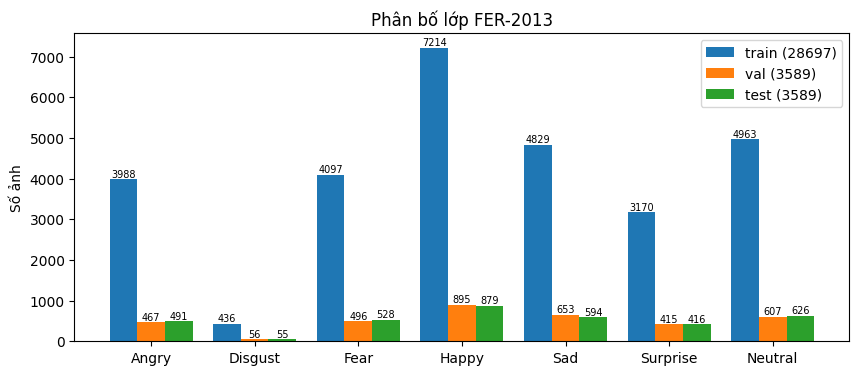

Train:  Angry: 3988 (13.9%) | Disgust: 436 (1.5%) | Fear: 4097 (14.3%) | Happy: 7214 (25.1%) | Sad: 4829 (16.8%) | Surprise: 3170 (11.0%) | Neutral: 4963 (17.3%)
Tỉ lệ mất cân bằng lớn nhất / nhỏ nhất: 16.5 lần (Happy / Disgust)

Class weight (power = 0.5, tức căn bậc hai của nghịch đảo tần suất):
          số ảnh train  weight power=1  weight power=0.5 (dùng)
Angry             3988            1.03                     1.06
Disgust            436            9.40                     3.20
Fear              4097            1.00                     1.04
Happy             7214            0.57                     0.79
Sad               4829            0.85                     0.96
Surprise          3170            1.29                     1.19
Neutral           4963            0.83                     0.95


In [3]:
plot_class_distribution(data, save=RESULTS / "class_distribution.png")

w = class_weights(ytr, power=0.5)
print("\nClass weight (power = 0.5, tức căn bậc hai của nghịch đảo tần suất):")
print(pd.DataFrame({"số ảnh train": np.bincount(ytr, minlength=7),
                    "weight power=1": class_weights(ytr, power=1.0).round(2),
                    "weight power=0.5 (dùng)": w.round(2)}, index=CLASSES))

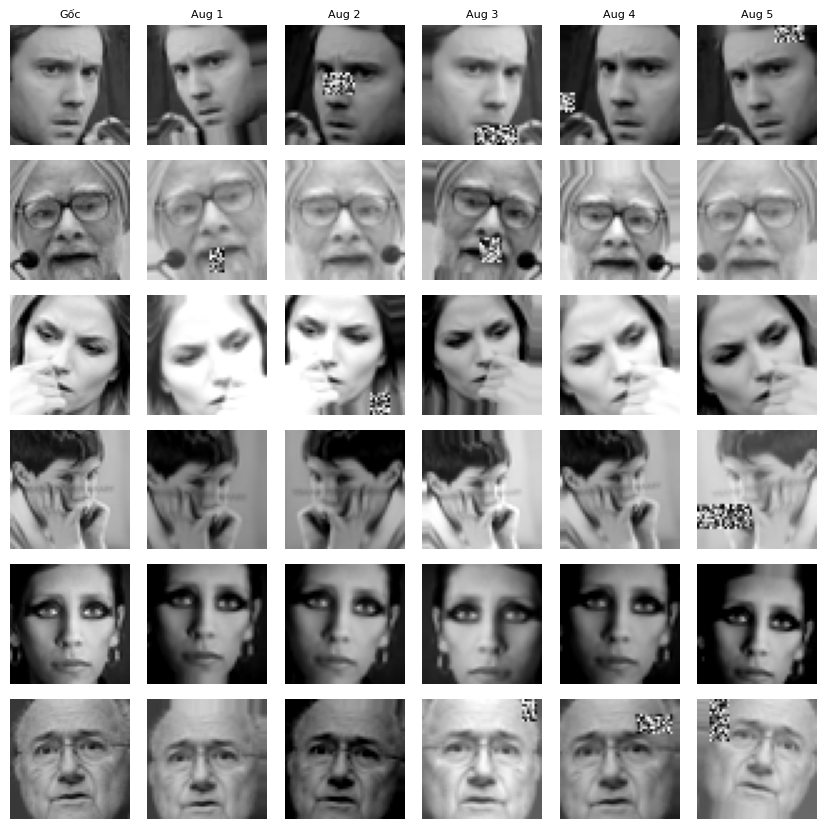

In [4]:
AUG = AugConfig(hflip=0.5, rotate=10, scale=0.10, translate=0.08,
                brightness=0.20, contrast=0.20, erase_p=0.25, erase_area=(0.02, 0.12))
show_augmentations(Xtr, AUG, DEVICE, save=RESULTS / "augmentation.png")

In [5]:
m1 = build_model("cnn", mean=(FER_MEAN,), std=(FER_STD,))
print(m1.net)
print(f"\nSố tham số M1: {count_params(m1):,}")

EmotionCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Sequential(
        (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Dropout2d(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(

In [6]:
M1_CFG = TrainConfig(
    epochs=60, batch_size=128,
    lr=3e-3,
    weight_decay=0.05,
    label_smoothing=0.10,
    class_weight_power=0.5,
    pct_start=0.15,
    patience=15, amp=True, seed=42, aug=AUG,
)
hist1 = fit(m1, data, M1_CFG, DEVICE, WEIGHTS / "cnn.pt")
json.dump(hist1, open(RESULTS / "history_m1.json", "w"))

Ep   1/60 | train loss 2.0481 acc 0.1891 | val loss 1.9487 acc 0.2689 F1 0.1394 | lr 2.07e-04 |  17.2s *
Ep   2/60 | train loss 1.9963 acc 0.2189 | val loss 1.8899 acc 0.2889 F1 0.2039 | lr 4.57e-04 |  14.7s *
Ep   3/60 | train loss 1.9029 acc 0.2940 | val loss 1.7242 acc 0.4313 F1 0.2979 | lr 8.41e-04 |  15.6s *
Ep   4/60 | train loss 1.7410 acc 0.4120 | val loss 1.6399 acc 0.4614 F1 0.3730 | lr 1.31e-03 |  13.8s *
Ep   5/60 | train loss 1.6513 acc 0.4695 | val loss 1.5490 acc 0.5130 F1 0.4150 | lr 1.81e-03 |  15.1s *
Ep   6/60 | train loss 1.6113 acc 0.4894 | val loss 1.5492 acc 0.5266 F1 0.4066 | lr 2.28e-03 |  14.5s 
Ep   7/60 | train loss 1.5758 acc 0.5090 | val loss 1.5240 acc 0.5361 F1 0.4294 | lr 2.66e-03 |  12.8s *
Ep   8/60 | train loss 1.5449 acc 0.5265 | val loss 1.4660 acc 0.5573 F1 0.4901 | lr 2.91e-03 |  14.4s *
Ep   9/60 | train loss 1.5180 acc 0.5382 | val loss 1.4763 acc 0.5316 F1 0.4507 | lr 3.00e-03 |  12.0s 
Ep  10/60 | train loss 1.4970 acc 0.5484 | val loss 1.434

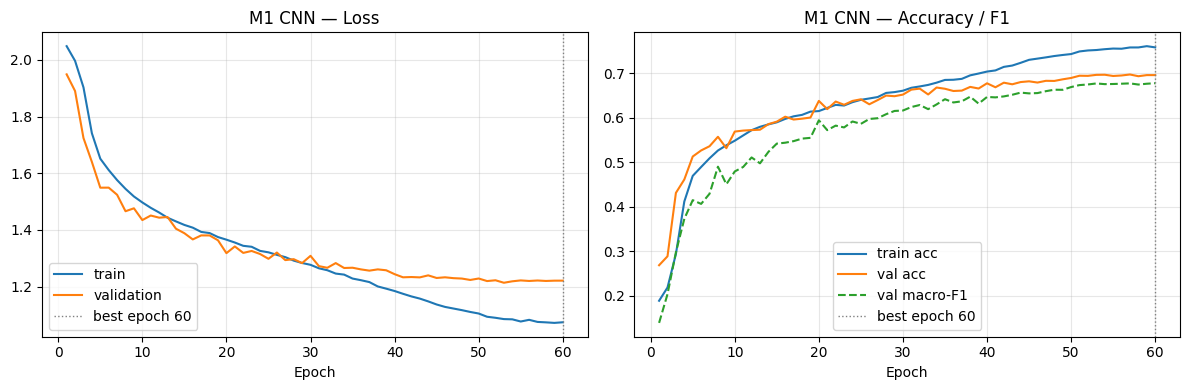

In [7]:
plot_history(hist1, "M1 CNN", save=RESULTS / "history_m1.png")

===== M1 CNN trên tập TEST (3589 ảnh) =====
Accuracy: 0.7086 | Macro-F1: 0.6947
              precision    recall  f1-score   support

       Angry      0.632     0.652     0.642       491
     Disgust      0.719     0.745     0.732        55
        Fear      0.579     0.456     0.511       528
       Happy      0.910     0.906     0.908       879
         Sad      0.583     0.566     0.574       594
    Surprise      0.793     0.812     0.803       416
     Neutral      0.643     0.752     0.693       626

    accuracy                          0.709      3589
   macro avg      0.694     0.699     0.695      3589
weighted avg      0.706     0.709     0.705      3589



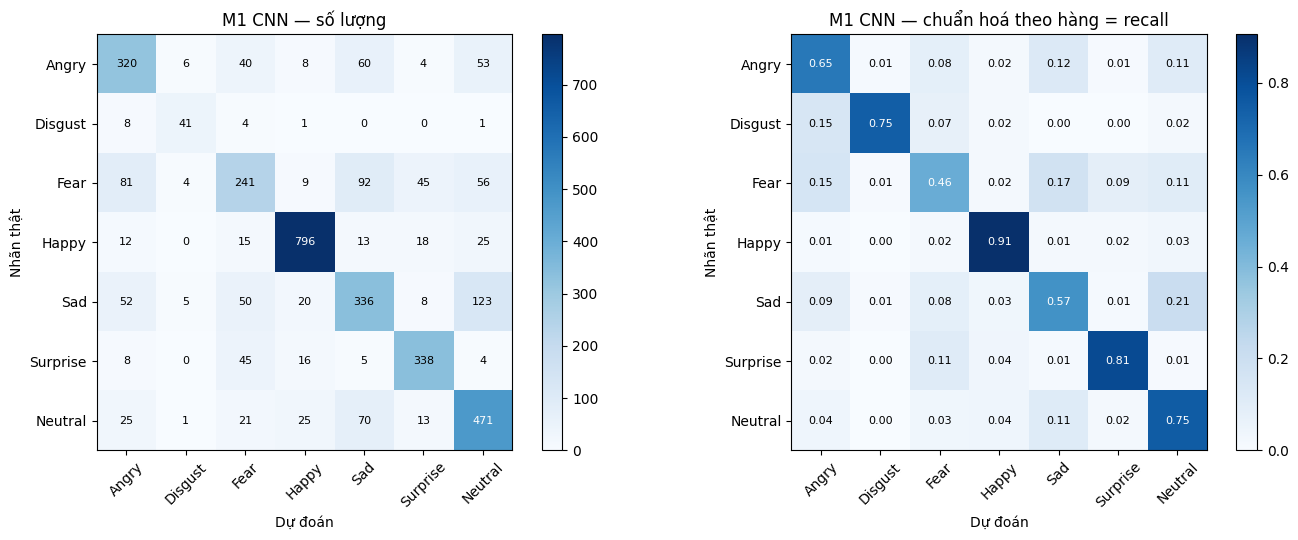

Các cặp nhầm lẫn nhiều nhất (thật -> dự đoán, % của lớp thật):
  Sad      -> Neutral : 20.7% (123 ảnh)
  Fear     -> Sad     : 17.4% (92 ảnh)
  Fear     -> Angry   : 15.3% (81 ảnh)
  Disgust  -> Angry   : 14.5% (8 ảnh)
  Angry    -> Sad     : 12.2% (60 ảnh)


In [8]:
probs1 = evaluate(m1, Xte, DEVICE)
res1 = summarize(yte, probs1, "M1 CNN")
plot_confusion(yte, probs1.argmax(1), "M1 CNN", save=RESULTS / "confusion_m1.png")

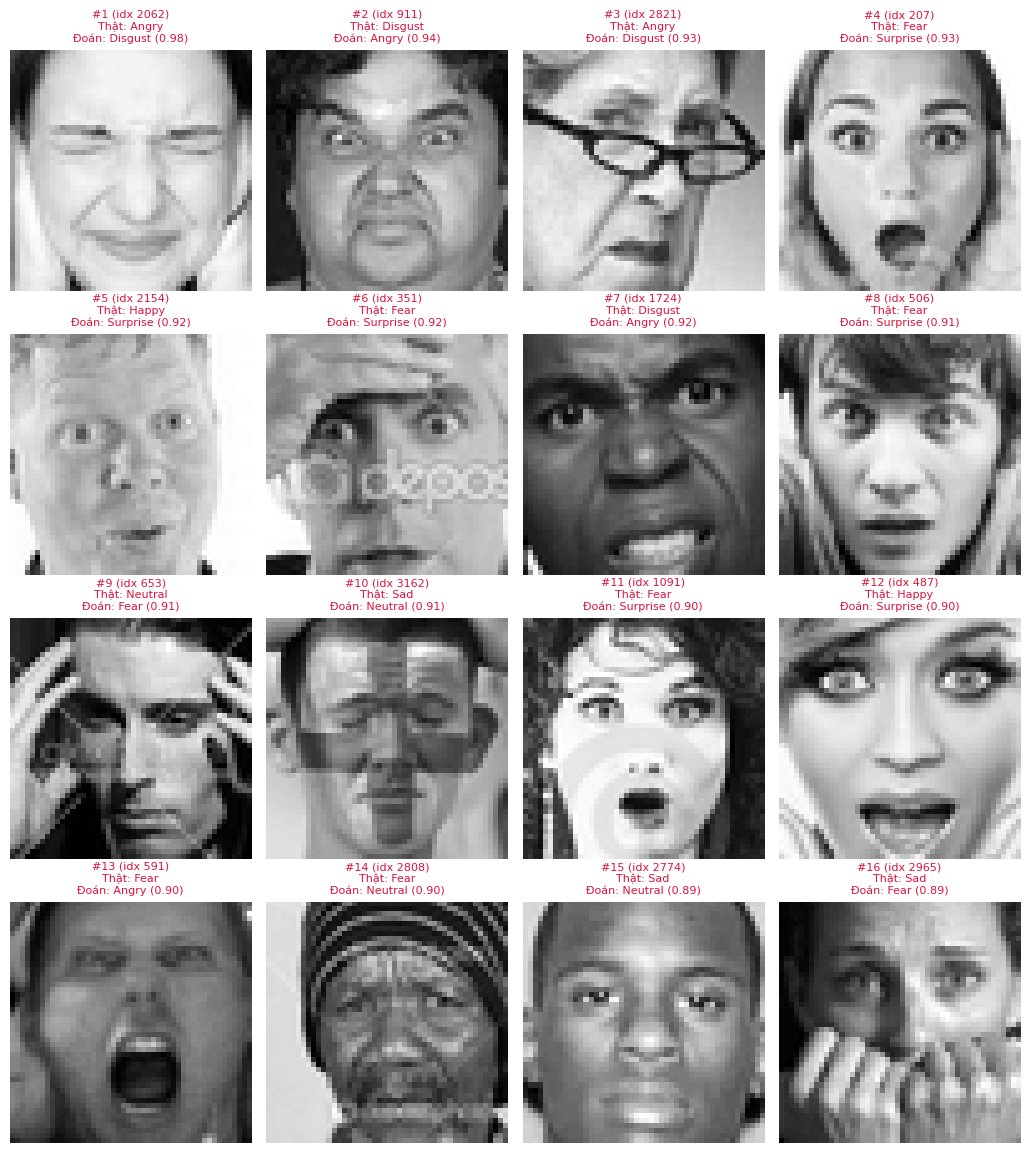

In [9]:
wrong1 = show_misclassified(Xte, yte, probs1, n=16, mode="confident", save=RESULTS / "misclassified_m1.png")

In [10]:
m2 = build_model("transfer", arch="resnet18", input_size=112, pretrained=True)
print(f"Số tham số M2: {count_params(m2):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\hovin/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:04<00:00, 10.3MB/s]


Số tham số M2: 11,180,103


In [11]:
M2_CFG = TrainConfig(
    epochs=30, batch_size=128,
    lr=1e-3,
    backbone_lr_mult=0.3,
    freeze_epochs=2,
    weight_decay=0.01,
    label_smoothing=0.10,
    class_weight_power=0.5,
    pct_start=0.10,
    patience=10, amp=True, seed=42, aug=AUG,
)
hist2 = fit(m2, data, M2_CFG, DEVICE, WEIGHTS / "transfer.pt")
json.dump(hist2, open(RESULTS / "history_m2.json", "w"))

Ep   1/30 | train loss 1.9701 acc 0.2860 | val loss 1.8151 acc 0.3787 F1 0.3023 | lr 1.00e-03 |  11.9s *
Ep   2/30 | train loss 1.8710 acc 0.3387 | val loss 1.8035 acc 0.3895 F1 0.3089 | lr 1.00e-03 |   7.4s *
--- Epoch 3: mở khoá backbone, bắt đầu fine-tune toàn bộ ---
Ep   3/30 | train loss 1.7214 acc 0.4316 | val loss 1.5388 acc 0.5316 F1 0.4822 | lr 3.13e-04 |  15.3s *
Ep   4/30 | train loss 1.4983 acc 0.5457 | val loss 1.4742 acc 0.5628 F1 0.5112 | lr 8.21e-04 |  14.5s *
Ep   5/30 | train loss 1.4034 acc 0.5986 | val loss 1.3929 acc 0.5979 F1 0.5598 | lr 1.00e-03 |  15.0s *
Ep   6/30 | train loss 1.3395 acc 0.6272 | val loss 1.3591 acc 0.6152 F1 0.5737 | lr 9.94e-04 |  14.3s *
Ep   7/30 | train loss 1.2900 acc 0.6493 | val loss 1.3277 acc 0.6333 F1 0.5950 | lr 9.81e-04 |  14.5s *
Ep   8/30 | train loss 1.2512 acc 0.6708 | val loss 1.2871 acc 0.6584 F1 0.6149 | lr 9.61e-04 |  14.7s *
Ep   9/30 | train loss 1.2228 acc 0.6831 | val loss 1.3181 acc 0.6403 F1 0.5968 | lr 9.33e-04 |  14

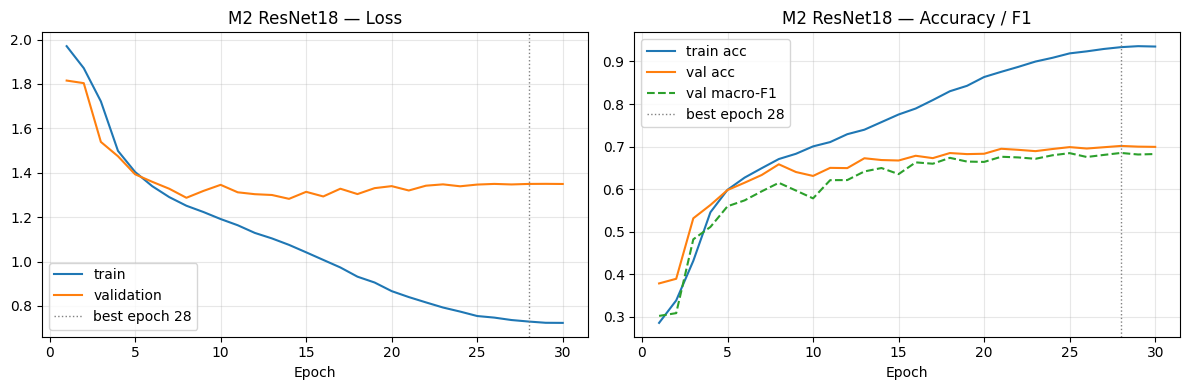

In [12]:
plot_history(hist2, "M2 ResNet18", save=RESULTS / "history_m2.png")

===== M2 ResNet18 trên tập TEST (3589 ảnh) =====
Accuracy: 0.7130 | Macro-F1: 0.7044
              precision    recall  f1-score   support

       Angry      0.650     0.668     0.659       491
     Disgust      0.759     0.745     0.752        55
        Fear      0.612     0.492     0.546       528
       Happy      0.912     0.894     0.903       879
         Sad      0.571     0.542     0.556       594
    Surprise      0.815     0.849     0.832       416
     Neutral      0.629     0.749     0.684       626

    accuracy                          0.713      3589
   macro avg      0.707     0.706     0.704      3589
weighted avg      0.712     0.713     0.711      3589



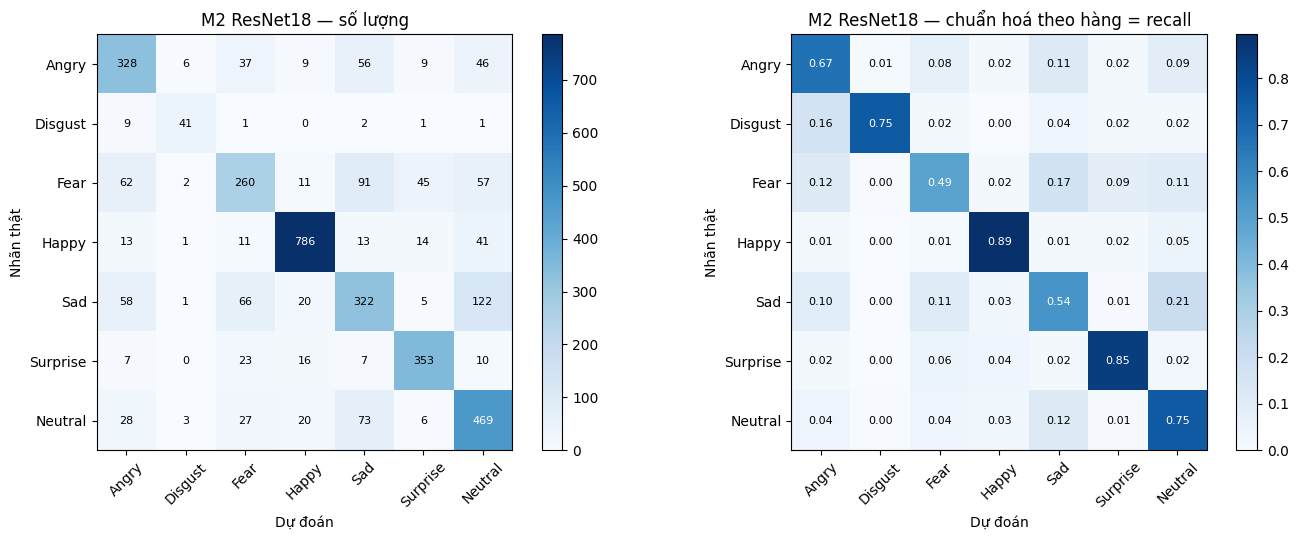

Các cặp nhầm lẫn nhiều nhất (thật -> dự đoán, % của lớp thật):
  Sad      -> Neutral : 20.5% (122 ảnh)
  Fear     -> Sad     : 17.2% (91 ảnh)
  Disgust  -> Angry   : 16.4% (9 ảnh)
  Fear     -> Angry   : 11.7% (62 ảnh)
  Neutral  -> Sad     : 11.7% (73 ảnh)


In [13]:
probs2 = evaluate(m2, Xte, DEVICE)
res2 = summarize(yte, probs2, "M2 ResNet18")
plot_confusion(yte, probs2.argmax(1), "M2 ResNet18", save=RESULTS / "confusion_m2.png")

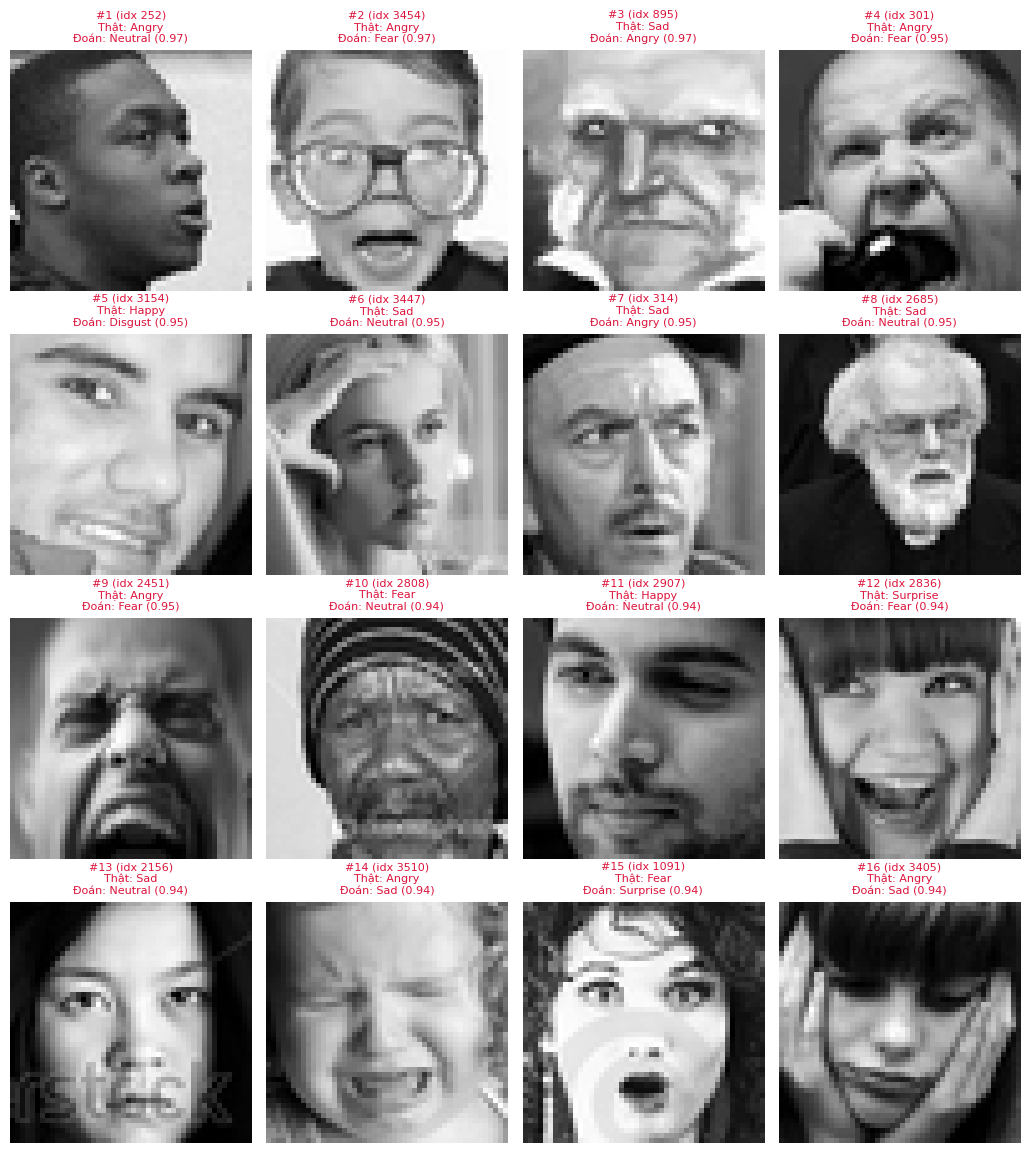

In [14]:
wrong2 = show_misclassified(Xte, yte, probs2, n=16, mode="confident", save=RESULTS / "misclassified_m2.png")

Số ảnh test cả M1 và M2 cùng sai: 738 / 3589 (20.6%) -> phần 'khó' hoặc nhãn nhiễu của FER-2013


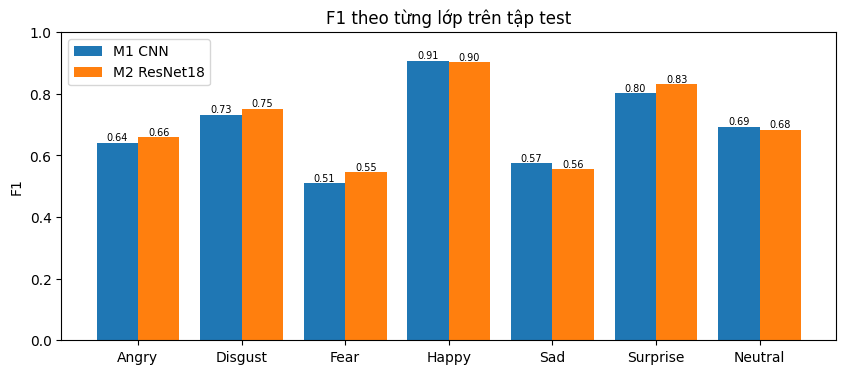

In [15]:
both = np.intersect1d(np.where(probs1.argmax(1) != yte)[0], np.where(probs2.argmax(1) != yte)[0])
print(f"Số ảnh test cả M1 và M2 cùng sai: {len(both)} / {len(yte)} "
      f"({len(both) / len(yte):.1%}) -> phần 'khó' hoặc nhãn nhiễu của FER-2013")
plot_per_class_f1([res1, res2], save=RESULTS / "per_class_f1.png")

In [17]:
rows = []
for name, model, res, key in [("M1 CNN tự thiết kế", m1, res1, "cnn"), ("M2 ResNet18 (TL)", m2, res2, "transfer")]:
    onnx_path = export_onnx(model, WEIGHTS / f"{key}.onnx")
    diff = onnx_max_diff(model, onnx_path)
    assert diff < 1e-3, f"ONNX lệch PyTorch quá nhiều: {diff}"
    t, o = latency_torch(model), latency_onnx(onnx_path)
    rows.append({
        "Mô hình": name,
        "Accuracy (test)": round(res["accuracy"], 4),
        "Macro-F1 (test)": round(res["macro_f1"], 4),
        "Số tham số (M)": round(count_params(model) / 1e6, 2),
        "Kích thước ONNX (MB)": round(onnx_path.stat().st_size / 2**20, 1),
        "CPU PyTorch (ms)": round(t["latency_ms"], 2),
        "CPU ONNX (ms)": round(o["latency_ms"], 2),
        "FPS model-only (ONNX)": round(o["fps"], 1),
        "Thời gian train (phút)": round((hist1 if key == "cnn" else hist2)["train_time_min"], 1),
    })
m3 = pd.DataFrame(rows).set_index("Mô hình")
m3.to_csv(RESULTS / "m3_comparison.csv")
m3.T

Mô hình,M1 CNN tự thiết kế,M2 ResNet18 (TL)
Accuracy (test),0.7086,0.7130
Macro-F1 (test),0.6947,0.7044
Số tham số (M),4.8200,11.1800
Kích thước ONNX (MB),18.4000,42.6000
CPU PyTorch (ms),8.2000,14.9500
CPU ONNX (ms),4.9700,5.1700
FPS model-only (ONNX),201.1000,193.4000
Thời gian train (phút),12.5000,7.2000


In [18]:
summary = {"M1": res1, "M2": res2, "data": {k: int(len(v[1])) for k, v in data.items()},
           "m3": json.loads(m3.reset_index().to_json(orient="records", force_ascii=False))}
json.dump(summary, open(RESULTS / "summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("Đã lưu weights:", sorted(p.name for p in WEIGHTS.iterdir()))
print("Đã lưu hình cho báo cáo:", sorted(p.name for p in RESULTS.iterdir()))

Đã lưu weights: ['.gitkeep', 'cnn.json', 'cnn.onnx', 'cnn.pt', 'face_detection_yunet_2023mar.onnx', 'transfer.json', 'transfer.onnx', 'transfer.pt']
Đã lưu hình cho báo cáo: ['augmentation.png', 'class_distribution.png', 'confusion_m1.png', 'confusion_m2.png', 'history_m1.json', 'history_m1.png', 'history_m2.json', 'history_m2.png', 'm3_comparison.csv', 'misclassified_m1.png', 'misclassified_m2.png', 'per_class_f1.png', 'summary.json']


In [19]:
from predict import EmotionPredictor
for key in ("cnn", "transfer"):
    p = EmotionPredictor(WEIGHTS / f"{key}.pt", backend="onnx")
    acc = (p.predict_batch(list(Xte[:500])).argmax(1) == yte[:500]).mean()
    print(f"{key:9s} backend={p.backend}: accuracy trên 500 ảnh test đầu = {acc:.3f}")

cnn       backend=onnx: accuracy trên 500 ảnh test đầu = 0.678
transfer  backend=onnx: accuracy trên 500 ảnh test đầu = 0.696
